In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker

In [35]:
path_master_dataset = "Master/"
pathDataCleaned = 'dataCleaned/'

## Customer - Khách hàng

In [4]:
dfCustomers = pd.read_csv(path_master_dataset + "customers.csv")
dfCustomers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121930 entries, 0 to 121929
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   customer_id          121930 non-null  int64 
 1   zip                  121930 non-null  int64 
 2   city                 121930 non-null  object
 3   signup_date          121930 non-null  object
 4   gender               121930 non-null  object
 5   age_group            121930 non-null  object
 6   acquisition_channel  121930 non-null  object
dtypes: int64(2), object(5)
memory usage: 6.5+ MB


In [5]:
print(dfCustomers.shape)

(121930, 7)


In [6]:
dfCustomers.head()

,customer_id,zip,city,signup_date,gender,age_group,acquisition_channel
0,1,15201,Hai Phong,2021-12-30,Female,35-44,social_media
1,2,15201,Hai Phong,2013-12-27,Female,45-54,email_campaign
2,3,15201,Hai Phong,2018-07-24,Female,18-24,organic_search
3,4,15201,Hai Phong,2017-11-29,Male,35-44,referral
4,5,15201,Hai Phong,2022-09-23,Male,55+,organic_search


In [12]:
dfCustomers.tail()

,customer_id,zip,city,signup_date,gender,age_group,acquisition_channel
121925,157556,59936,Vung Tau,2016-03-03,Female,18-24,direct
121926,157557,59936,Vung Tau,2021-05-11,Female,45-54,social_media
121927,157558,59936,Vung Tau,2017-02-27,Female,25-34,referral
121928,157561,59937,Buon Ma Thuot,2018-10-15,Non-binary,45-54,paid_search
121929,157563,59937,Buon Ma Thuot,2018-08-23,Male,35-44,social_media


In [14]:
dfCustomers.describe()

,customer_id,zip
count,121930.000000,121930.000000
mean,78736.898663,50990.165595
std,45492.202886,26871.914605
min,1.000000,1001.000000
25%,39343.500000,28689.250000
50%,78784.500000,49835.000000
75%,118156.750000,73488.000000
max,157563.000000,99950.000000


In [16]:
dfCustomers.describe(include='O')


,city,signup_date,gender,age_group,acquisition_channel
count,121930,121930,121930,121930,121930
unique,42,3941,3,5,6
top,Cam Pha,2022-06-02,Female,25-34,organic_search
freq,4398,78,59640,36342,36450


### 1. Mô Tả Bảng

Bảng **`customers`** lưu trữ thông tin hồ sơ của khách hàng, bao gồm định danh, địa lý, thời gian đăng ký và các thuộc tính nhân khẩu học. Đây là bảng trung tâm liên kết với các bảng giao dịch khác trong hệ thống.

---

### 2. Schema & Mô Tả Cột

| STT | Cột | Kiểu dữ liệu | Ràng buộc | Mô tả |
|-----|-----|-------------|-----------|-------|
| 0 | `customer_id` | `int64` | PK · NOT NULL | Khóa chính định danh khách hàng |
| 1 | `zip` | `int64` | FK → `geography.zip` · NOT NULL | Mã bưu chính |
| 2 | `city` | `str` | NOT NULL | Tên thành phố của khách hàng |
| 3 | `signup_date` | `str` (date) | NOT NULL | Ngày đăng ký tài khoản (YYYY-MM-DD) |
| 4 | `gender` | `str` | NOT NULL | Giới tính khách hàng |
| 5 | `age_group` | `str` | NOT NULL | Nhóm tuổi khách hàng |
| 6 | `acquisition_channel` | `str` | NOT NULL | Kênh tiếp thị mà khách hàng đăng ký qua |

In [19]:
dfCustomers['signup_date'] = pd.to_datetime(dfCustomers['signup_date'], format='%Y-%m-%d', errors='coerce')
dfCustomers["customer_id"].duplicated().sum()

0

In [27]:
# Kiểm tra toàn vẹn tham chiếu với geography
dfGeography = pd.read_csv(path_master_dataset + 'geography.csv')

zip_geo = set(dfGeography['zip'].unique())
zip_cust = set(dfCustomers['zip'].unique())

in_cus__not_in_geo = zip_cust - zip_geo          # zip trong customers nhưng không có trong geography
missing_geo = zip_geo - zip_cust          # zip trong geography nhưng không có customers nào

orphan_rows = dfCustomers[dfCustomers['zip'].isin(in_cus__not_in_geo)]

print("=== Toàn vẹn tham chiếu: customers.zip → geography.zip ===")
print(f"Distinct ZIP trong customers  : {len(zip_cust):,}")
print(f"Distinct ZIP trong geography  : {len(zip_geo):,}")
print(f"ZIP hợp lệ (có trong geography): {len(zip_cust & zip_geo):,}")
print(f"ZIP có trong customer nhưng không có trong geography: {len(in_cus__not_in_geo):,}")
print(f"  → Số dòng bị ảnh hưởng: {len(orphan_rows):,}")
print(f"ZIP trong geography không có customer: {len(missing_geo):,}")

if len(in_cus__not_in_geo) > 0:
    print("\n zip trong customers nhưng không có trong geography:")
    print(sorted(in_cus__not_in_geo))
else:
    print("\nToàn vẹn tham chiếu OK — Không có ZIP vô định.")


=== Toàn vẹn tham chiếu: customers.zip → geography.zip ===
Distinct ZIP trong customers  : 31,491
Distinct ZIP trong geography  : 39,948
ZIP hợp lệ (có trong geography): 31,491
ZIP có trong customer nhưng không có trong geography: 0
  → Số dòng bị ảnh hưởng: 0
ZIP trong geography không có customer: 8,457

Toàn vẹn tham chiếu OK — Không có ZIP vô định.


In [29]:
cols = ["city", "gender", "age_group", "acquisition_channel"]

for col in cols:
    vc = dfCustomers[col].value_counts(dropna=False)
    pct = (vc / len(dfCustomers) * 100).round(2)
    summary = pd.DataFrame({"count": vc, "pct (%)": pct})

    print(f"{'─'*50}")
    print(f"Cột: `{col}`  |  Distinct: {dfCustomers[col].nunique()}  |  Null: {dfCustomers[col].isna().sum()}")
    print(summary.to_string())
    print()


──────────────────────────────────────────────────
Cột: `city`  |  Distinct: 42  |  Null: 0
                     count  pct (%)
city                               
Cam Pha               4398     3.61
Thai Nguyen           4347     3.57
Phu Ly                4243     3.48
Hanoi                 4240     3.48
Ha Long               4236     3.47
Bac Ninh              4172     3.42
Hai Phong             4170     3.42
Nam Dinh              4169     3.42
Bac Giang             4160     3.41
Ninh Binh             4081     3.35
Son Tay               4075     3.34
Viet Tri              4054     3.32
Uong Bi               4026     3.30
Dong Hoi              3912     3.21
Kon Tum               3838     3.15
Lao Cai               3807     3.12
Hoi An                3760     3.08
Phan Thiet            3749     3.07
Phan Rang-Thap Cham   3734     3.06
Hue                   3719     3.05
Tuy Hoa               3674     3.01
Da Nang               3616     2.97
Quang Ngai            3616     2.97
Tam Ky  

In [37]:
dfCustomers.to_csv(pathDataCleaned + 'customers_cleaned', index=False)
print(f"Đã lưu: {pathDataCleaned + 'customers_cleaned'}")

Đã lưu: dataCleaned/customers_cleaned


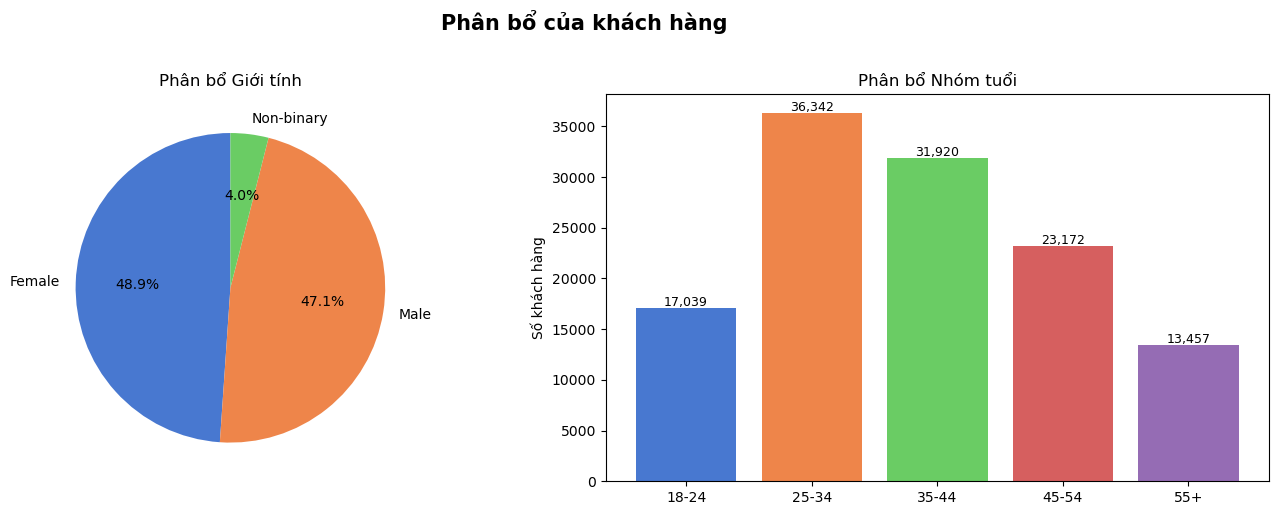

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender
gender_vc = dfCustomers['gender'].value_counts()
axes[0].pie(gender_vc, labels=gender_vc.index, autopct='%1.1f%%',
            colors=sns.color_palette("muted"), startangle=90)
axes[0].set_title("Phân bổ Giới tính")

# Age Group
age_order = ['18-24', '25-34', '35-44', '45-54', '55+']
age_vc = dfCustomers['age_group'].value_counts().reindex(age_order)
axes[1].bar(age_vc.index, age_vc.values, color=sns.color_palette("muted", len(age_order)))
axes[1].set_title("Phân bổ Nhóm tuổi")
axes[1].set_ylabel("Số khách hàng")
for i, v in enumerate(age_vc.values):
    axes[1].text(i, v + 200, f"{v:,}", ha='center', fontsize=9)

plt.suptitle("Phân bổ của khách hàng", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


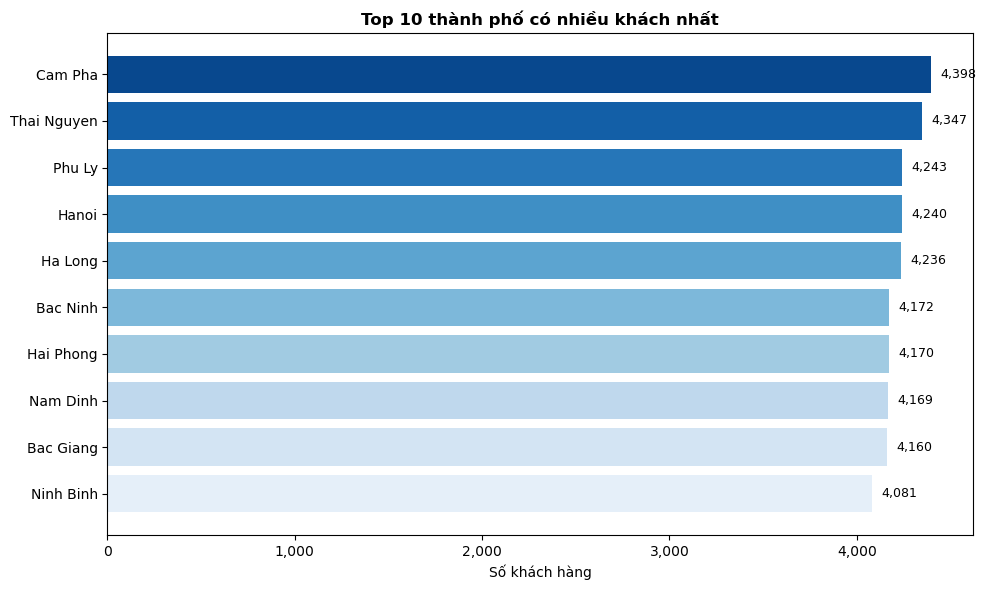

In [51]:
city_vc = dfCustomers['city'].value_counts()
N = 10

fig, ax = plt.subplots(figsize=(10, 6))

top_cities = city_vc.head(N)
colors = sns.color_palette("Blues", N)

ax.barh(top_cities.index[::-1], top_cities.values[::-1], color=colors)
ax.set_title(f"Top {N} thành phố có nhiều khách nhất", fontweight='bold')
ax.set_xlabel("Số khách hàng")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

for i, (city, v) in enumerate(zip(top_cities.index[::-1], top_cities.values[::-1])):
    ax.text(v + 50, i, f"{v:,}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


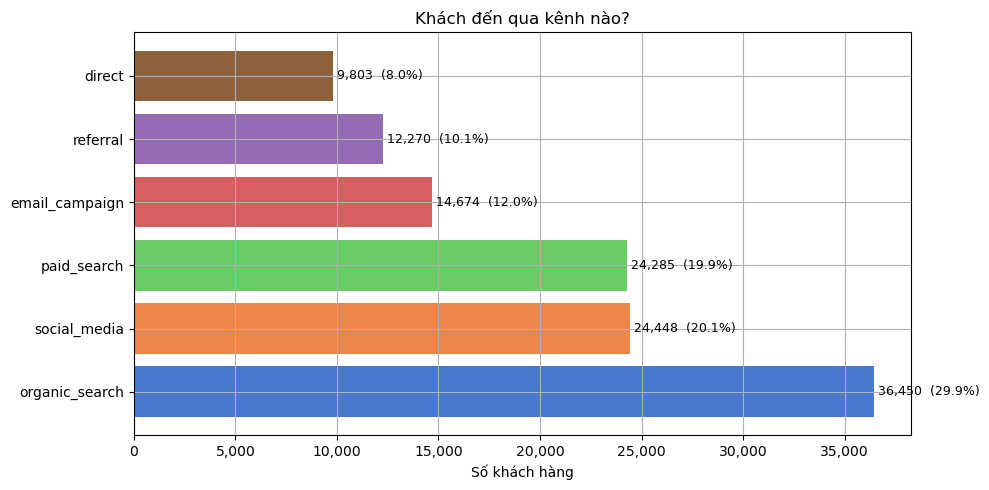

In [57]:
fig, ax = plt.subplots(figsize=(10, 5))

ch_vc = dfCustomers['acquisition_channel'].value_counts()
bars = ax.barh(ch_vc.index, ch_vc.values, color=sns.color_palette("muted", len(ch_vc)))
ax.set_title("Khách đến qua kênh nào?")
ax.set_xlabel("Số khách hàng")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

for bar, v in zip(bars, ch_vc.values):
    ax.text(v + 200, bar.get_y() + bar.get_height()/2,
            f"{v:,}  ({v/len(dfCustomers)*100:.1f}%)", va='center', fontsize=9)
plt.grid("--")
plt.tight_layout()
plt.show()


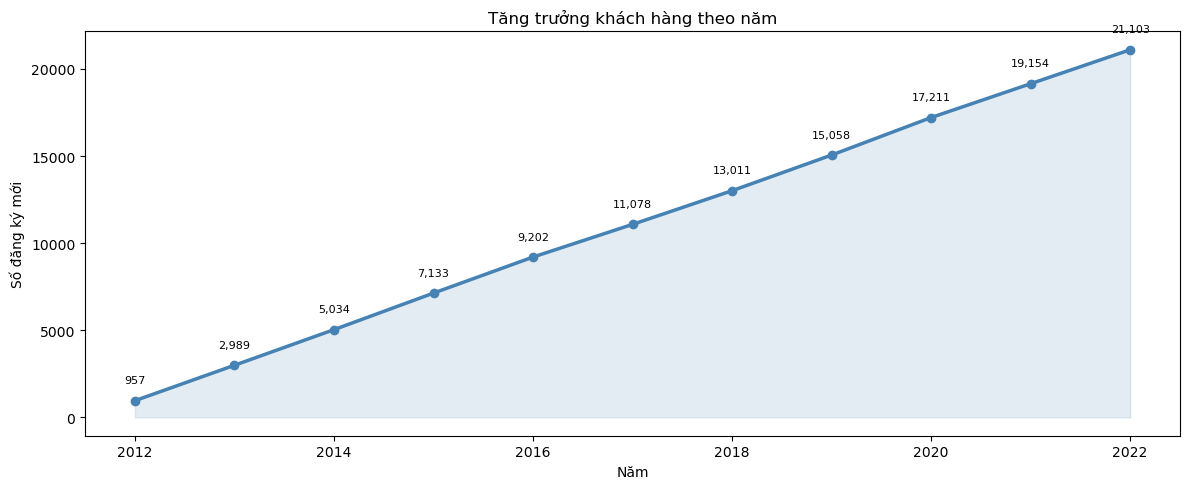

In [75]:
plt.figure(figsize=(12, 5))

yearly = dfCustomers.groupby(dfCustomers['signup_date'].dt.year).size()
plt.plot(yearly.index, yearly.values, marker='o', linewidth=2.5, color='steelblue')
plt.fill_between(yearly.index, yearly.values, alpha=0.15, color='steelblue')
plt.title("Tăng trưởng khách hàng theo năm")
plt.xlabel("Năm")
plt.ylabel("Số đăng ký mới")

for x, y in zip(yearly.index, yearly.values):
    plt.text(x, y + 1000, f"{y:,}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()


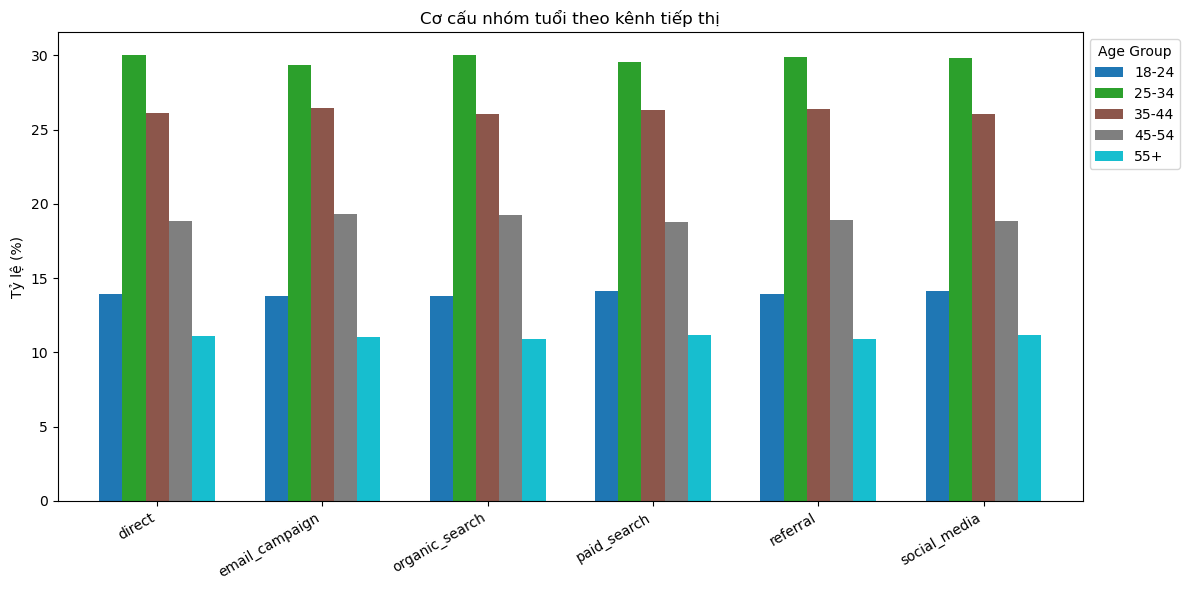

In [77]:
fig, ax = plt.subplots(figsize=(12, 6))

cross = pd.crosstab(dfCustomers['acquisition_channel'], dfCustomers['age_group'])
cross = cross[['18-24', '25-34', '35-44', '45-54', '55+']]
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

cross_pct.plot(kind='bar', ax=ax, colormap='tab10', width=0.7)
ax.set_title("Cơ cấu nhóm tuổi theo kênh tiếp thị")
ax.set_xlabel("")
ax.set_ylabel("Tỷ lệ (%)")
ax.legend(title="Age Group", bbox_to_anchor=(1, 1))
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()


#### Phân bố về con người

- **Giới tính** phân bổ gần như **cân bằng hoàn toàn**: Female 48.9% — Male 47.1% — Non-binary 4.0%. Dữ liệu không bị thiên lệch giới tính, tạo điều kiện phân tích công bằng.
- **Nhóm tuổi 25–34 chiếm đông nhất** (36,342 khách — ~29.8%), tiếp theo là 35–44 (31,920). Hai nhóm này cộng lại chiếm hơn **56% tổng khách hàng** → đây là tệp khách hàng **lao động trẻ, thu nhập đang tăng**, có tiềm năng mua sắm cao.
- Nhóm **55+ chỉ chiếm 11%** (13,457 khách) — phân khúc cao tuổi còn nhiều dư địa khai thác.

#### Địa lý — Thành phố

- Top 10 thành phố có số khách **rất đồng đều**, dao động trong khoảng **4,081 – 4,398** — không có thành phố nào chiếm ưu thế tuyệt đối.
- **Cam Pha** dẫn đầu (4,398), bên cạnh các đô thị lớn như **Hà Nội** (4,240) và **Hải Phòng** (4,170). Điều này cho thấy nền tảng khách hàng **trải rộng địa lý**, không tập trung vào một trung tâm duy nhất.

#### Kênh tiếp thị

- **Organic Search** là kênh hiệu quả nhất với **36,450 khách (29.9%)** — phản ánh thương hiệu có **độ nhận diện tự nhiên tốt** hoặc đầu tư SEO hiệu quả.
- **Social Media** (20.1%) và **Paid Search** (19.9%) xếp thứ 2–3 sát nút, tổng cộng chiếm ~40% — cho thấy ngân sách marketing kỹ thuật số đang hoạt động song song hiệu quả.
- **Direct** chỉ chiếm 8% — tỷ lệ khách hàng trung thành truy cập trực tiếp còn thấp, có thể cải thiện qua loyalty program.

#### Tăng trưởng theo thời gian

- Số khách đăng ký mới tăng **tuyến tính bền vững** từ 957 (2012) lên **21,103 (2022)** — tốc độ tăng trưởng trung bình ~**+2,000 khách/năm**.
- Không có năm nào sụt giảm, cho thấy business **ổn định và có đà tăng trưởng dài hạn**.

#### Cross: Kênh × Nhóm tuổi

- Cơ cấu nhóm tuổi **đồng nhất hoàn toàn** qua tất cả các kênh tiếp thị (25–34 ~30%, 35–44 ~26%, 45–54 ~19%, 18–24 ~14%, 55+ ~11%).
- Điều này cho thấy **không có kênh nào đặc thù thu hút một nhóm tuổi riêng biệt** → chiến lược phân khúc theo kênh hiện tại chưa được cá nhân hoá theo độ tuổi. Đây là **cơ hội tối ưu hoá targeting**.

## Geography - Địa lý

In [85]:
dfgeography = pd.read_csv(path_master_dataset + "geography.csv")
dfgeography.head()

,zip,city,region,district
0,15201,Hai Phong,East,District #13
1,15202,Phu Ly,East,District #13
2,15203,Viet Tri,East,District #13
3,15204,Bac Giang,East,District #13
4,15205,Bac Giang,East,District #13


In [87]:
dfgeography.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39948 entries, 0 to 39947
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   zip       39948 non-null  int64 
 1   city      39948 non-null  object
 2   region    39948 non-null  object
 3   district  39948 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.2+ MB


In [91]:
dfgeography.describe(include = "O")

,city,region,district
count,39948,39948,39948
unique,42,3,39
top,Cam Pha,East,District #25
freq,1403,18929,1597




Bảng **`geography`** là bảng tra cứu địa lý, ánh xạ từng mã bưu chính (`zip`) sang thông tin hành chính đầy đủ. Đây là bảng dimension phục vụ join với `customers` và các bảng giao dịch để phân tích theo vùng miền.

---


| # | Cột | Kiểu | Ràng buộc | Mô tả |
|---|-----|------|-----------|-------|
| 0 | `zip` | `int64` | PK · NOT NULL | Mã bưu chính — định danh duy nhất |
| 1 | `city` | `str` | NOT NULL | Tên thành phố |
| 2 | `region` | `str` | NOT NULL | Vùng địa lý (`East`, `West`, `Central`) |
| 3 | `district` | `str` | NOT NULL | Tên quận/huyện (`District #XX`) |

In [94]:
dfgeography.isnull().sum()

zip         0
city        0
region      0
district    0
dtype: int64

In [96]:
dfgeography.duplicated().sum()


0

In [98]:
dfgeography.to_csv(pathDataCleaned + "geography_cleaned.csv")

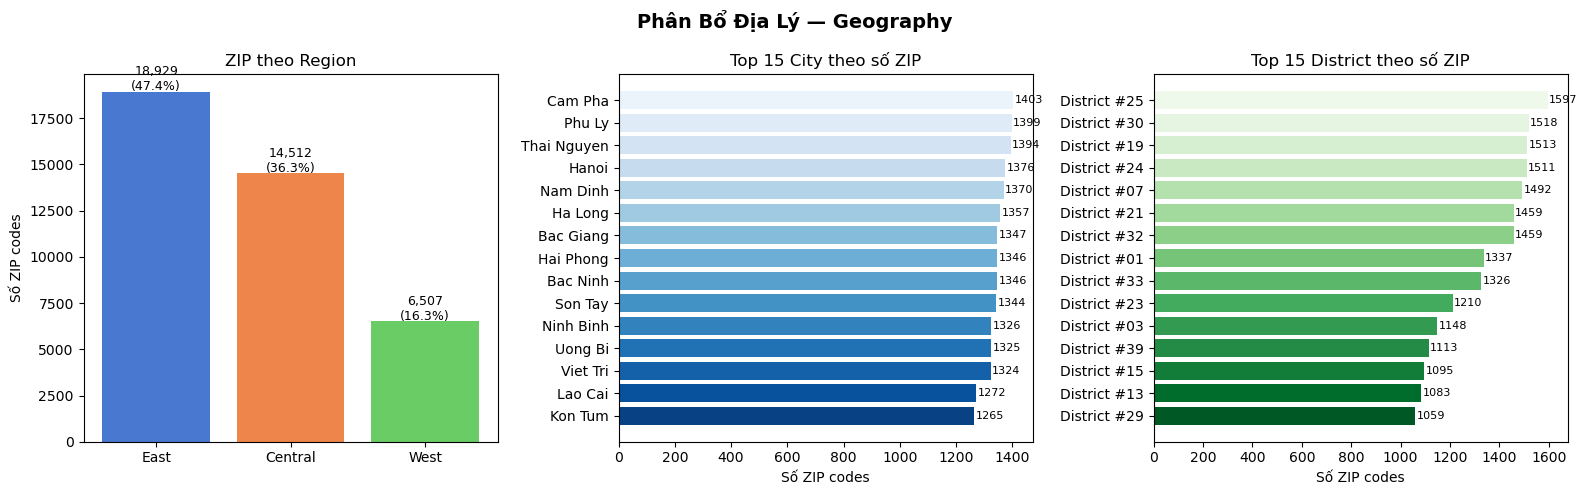

In [102]:
# Phân phối Region
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Region
region_vc = dfgeography['region'].value_counts()
axes[0].bar(region_vc.index, region_vc.values, color=sns.color_palette("muted", 3))
axes[0].set_title("ZIP theo Region")
axes[0].set_ylabel("Số ZIP codes")
for i, v in enumerate(region_vc.values):
    axes[0].text(i, v + 100, f"{v:,}\n({v/len(dfgeography)*100:.1f}%)", ha='center', fontsize=9)

# Top 15 cities
city_vc = dfgeography['city'].value_counts().head(15)
axes[1].barh(city_vc.index[::-1], city_vc.values[::-1], color=sns.color_palette("Blues_r", 15))
axes[1].set_title("Top 15 City theo số ZIP")
axes[1].set_xlabel("Số ZIP codes")
for i, v in enumerate(city_vc.values[::-1]):
    axes[1].text(v + 5, i, str(v), va='center', fontsize=8)

# Top 15 districts
dist_vc = dfgeography['district'].value_counts().head(15)
axes[2].barh(dist_vc.index[::-1], dist_vc.values[::-1], color=sns.color_palette("Greens_r", 15))
axes[2].set_title("Top 15 District theo số ZIP")
axes[2].set_xlabel("Số ZIP codes")
for i, v in enumerate(dist_vc.values[::-1]):
    axes[2].text(v + 5, i, str(v), va='center', fontsize=8)

plt.suptitle("Phân Bổ Địa Lý — Geography", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


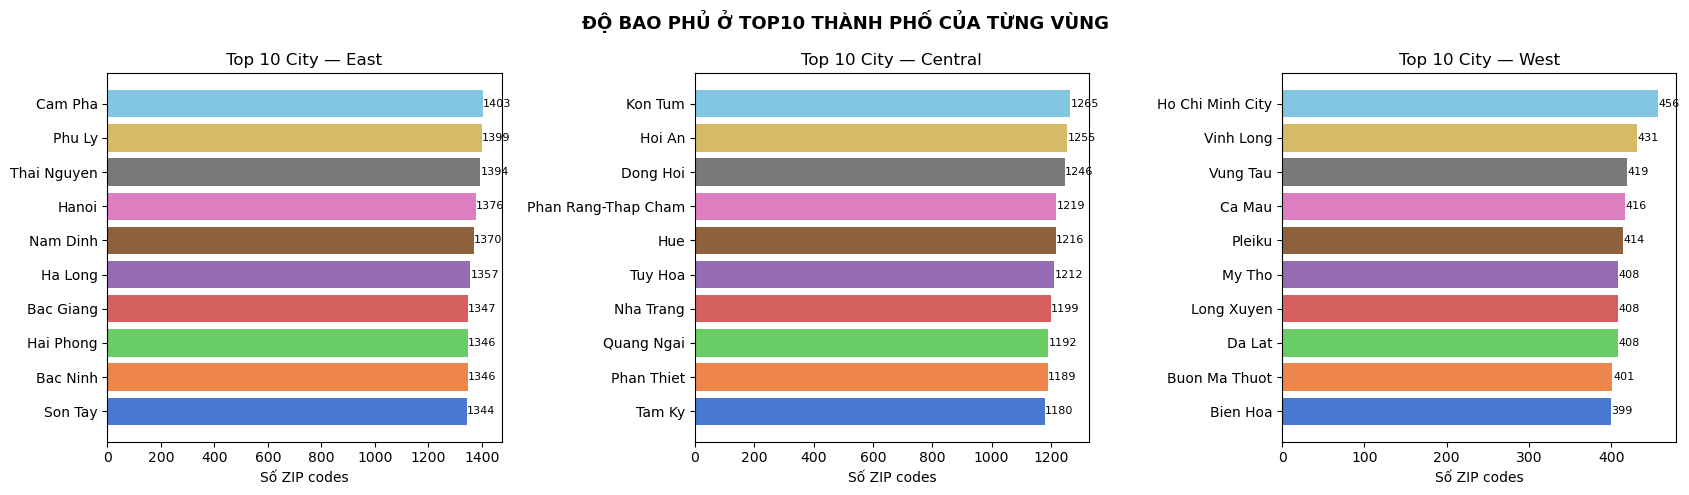

In [114]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, region in zip(axes, dfgeography['region'].unique()):
    sub = dfgeography[dfgeography['region'] == region]['city'].value_counts().head(10)
    ax.barh(sub.index[::-1], sub.values[::-1], color=sns.color_palette("muted", len(sub)))
    ax.set_title(f"Top 10 City — {region}")
    ax.set_xlabel("Số ZIP codes")
    for i, v in enumerate(sub.values[::-1]):
        ax.text(v + 1, i, str(v), va='center', fontsize=8)

plt.suptitle("ĐỘ BAO PHỦ Ở TOP10 THÀNH PHỐ CỦA TỪNG VÙNG", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## Products - Danh mục sản phẩm

In [116]:
dfProduct = pd.read_csv(path_master_dataset + "products.csv")
dfProduct.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2412 entries, 0 to 2411
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    2412 non-null   int64  
 1   product_name  2412 non-null   object 
 2   category      2412 non-null   object 
 3   segment       2412 non-null   object 
 4   size          2412 non-null   object 
 5   color         2412 non-null   object 
 6   price         2412 non-null   float64
 7   cogs          2412 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 150.9+ KB


## Thông tin dataset

| Cột          | Kiểu  | Mô tả                              |
|--------------|-------|------------------------------------|
| product_id   | int   | Khoá chính                         |
| product_name | str   | Tên sản phẩm                       |
| category     | str   | Danh mục sản phẩm                  |
| segment      | str   | Phân khúc thị trường của sản phẩm  |
| size         | str   | Kích cỡ sản phẩm                   |
| color        | str   | Nhãn màu sản phẩm                  |
| price        | float | Giá bán lẻ                         |
| cogs         | float | Giá vốn hàng bán                   |

> **Ràng buộc:** `cogs < price` với mọi sản phẩm.


In [118]:
dfProduct.head()

,product_id,product_name,category,segment,size,color,price,cogs
0,536,SaigonFlex UC-01,Streetwear,Everyday,S,green,11059.650000,9704.842875
1,537,SaigonFlex UC-02,Streetwear,Everyday,M,silver,9523.076013,5393.870254
2,538,SaigonFlex UC-03,Streetwear,Everyday,L,pink,15951.633158,11371.919278
3,539,SaigonFlex UC-04,Streetwear,Everyday,XL,yellow,15753.717299,8573.172954
4,540,SaigonFlex UC-05,Streetwear,Everyday,S,red,15766.334536,14063.570406


In [120]:
dfProduct.tail()

,product_id,product_name,category,segment,size,color,price,cogs
2407,1260,VietMode MP-28,Casual,Activewear,S,red,4603.340000,2553.933032
2408,1261,VietMode MP-29,Casual,Activewear,M,black,5983.876433,4653.660702
2409,1262,VietMode MP-30,Casual,Activewear,L,orange,5983.876433,5684.682611
2410,1263,VietMode MP-31,Casual,Activewear,XL,blue,5984.370000,5685.151500
2411,1264,VietMode MP-32,Casual,Activewear,S,white,5984.370000,3719.884392


In [122]:
dfProduct.describe()

,product_id,price,cogs
count,2412.000000,2412.000000,2412.000000
mean,1206.500000,4928.216231,3868.346732
std,696.428747,4776.737669,3878.584151
min,1.000000,9.056594,5.183829
25%,603.750000,59.444924,35.066367
50%,1206.500000,4399.605000,3184.934093
75%,1809.250000,7720.513784,5864.916462
max,2412.000000,40950.000000,38902.500000


In [124]:
dfProduct.describe(include="O")

,product_name,category,segment,size,color
count,2412,2412,2412,2412,2412
unique,2172,4,8,4,10
top,VietMode RP-29,Streetwear,Activewear,S,black
freq,3,1320,598,603,242


In [127]:
dfProduct.isnull().sum()

product_id      0
product_name    0
category        0
segment         0
size            0
color           0
price           0
cogs            0
dtype: int64

In [129]:
dfProduct.duplicated().sum()


0

- **Không có giá trị thiếu (null)** ở bất kỳ cột nào → dữ liệu sạch về mặt completeness.


**Thông tin sau khảo sát dữ liệu**
 
 Cột | Nhận xét |
|---|---|
| `product_id` | Khoá chính dạng số nguyên, không có giá trị thiếu. Cần kiểm tra tính duy nhất. |
| `product_name` | 2.412 bản ghi nhưng chỉ có **2.172 tên duy nhất** → tồn tại **240 tên trùng lặp**. Tên phổ biến nhất là `VietMode RP-01` (xuất hiện 3 lần). Có thể là các biến thể màu/size khác nhau của cùng một dòng sản phẩm. |
| `category` | Chỉ có **4 danh mục**, trong đó **Streetwear chiếm ưu thế** với 1.320/2.412 sản phẩm (~54.7%). |
| `segment` | **8 phân khúc** thị trường, phổ biến nhất là **Activewear** (598 sản phẩm, ~24.8%). Phân bố tương đối đa dạng. |
| `size` | **4 kích cỡ** (S, M, L, XL), trong đó **S** là phổ biến nhất (603 sản phẩm, ~25%) — phân bố khá đều giữa các size. |
| `color` | **10 màu** khác nhau, **black** là màu phổ biến nhất (242 sản phẩm, ~10%) — phân bố tương đối đồng đều. |
| `price` | Giá bán lẻ dạng `float64`. Ví dụ dao động từ ~9.500 đến ~15.900 VNĐ trong mẫu đầu. |
| `cogs` | Giá vốn hàng bán, **luôn nhỏ hơn `price`** theo ràng buộc dữ liệu → biên lợi nhuận gộp dương với mọi sản phẩm. |

In [140]:
# Kiểm tra ràng buộc cogs < price
dfProduct.loc[dfProduct["cogs"] >= dfProduct["price"]]

,product_id,product_name,category,segment,size,color,price,cogs


In [144]:
# Kiếm tra id có phải duy nhất hay không
dfProduct["product_id"].duplicated().sum()

0

## Promotions - Chương trình khuyến mã